# LogiTrack: Notebook 04: Statistical Analysis (Step 9)
Five hypothesis tests from the brief, plus two supporting tests. Significance level **α = 0.05** throughout. Each test follows the same layout: business question → hypotheses → formula → computation (manual formula checked against SciPy) → decision → business interpretation.

In [1]:
# --- Setup: make the project root importable and load shared helpers -------------
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from src import utils
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline
from scipy import stats
ALPHA = 0.05
df = pd.read_csv(utils.CLEANED_DIR / "logitrack_master_features.csv", parse_dates=["shipment_dt", "actual_dt"])
done = df[df["is_completed"] == 1].copy()      # completed deliveries (delay and transit time are defined)
results = []                                   # collected for reports/statistical_test_results.csv

def decide(p):
    return "Reject H0" if p < ALPHA else "Fail to reject H0"
print(df.shape, done.shape)

(3000, 58) (2712, 58)


## Test 1: Paired t-test (Q1 vs Q2 delivery time, same drivers)
**Business question:** Did delivery time change significantly between Q1 and Q2 for the same drivers?
* H₀: μ_diff = 0 (no change in delivery time) · H₁: μ_diff ≠ 0
* Formula: t = x̄_diff / (s_diff / √n)
* Variables: each driver's **mean delivery time (hours, `actual_dt − shipment_dt`)** in Q1 (Jan-Mar) and in Q2 (Apr-Jun), with 2024 and 2025 pooled. Only drivers with completed deliveries in both quarters are included (pairing).

Drivers paired: n = 75
Mean Q1 = 26.63 h | Mean Q2 = 26.00 h | mean diff (Q2-Q1) = -0.63 h
t (manual) = -0.5804 | t (scipy) = -0.5804 | p = 0.5634 -> Fail to reject H0
Shapiro-Wilk on differences p = 0.3151; Wilcoxon signed-rank (robustness) p = 0.5126
Supporting: delay hours Q1 = 7.07, Q2 = 7.12, t = 0.072, p = 0.9430


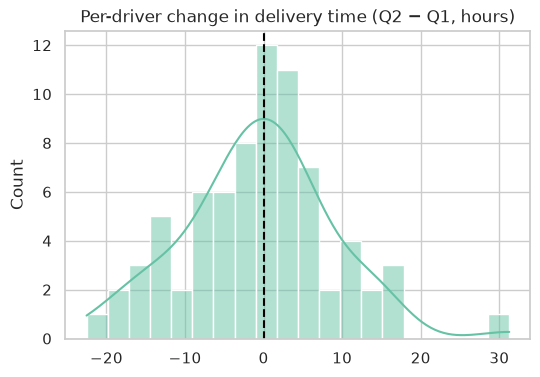

In [2]:
q = done[done["shipment_quarter"].isin(["Q1", "Q2"])]
paired = q.pivot_table(index="driver_id", columns="shipment_quarter", values="delivery_hours", aggfunc="mean").dropna()
diff = paired["Q2"] - paired["Q1"]
n = len(diff)
t_manual = diff.mean() / (diff.std(ddof=1) / np.sqrt(n))
t_stat, p_val = stats.ttest_rel(paired["Q2"], paired["Q1"])
shapiro_p = stats.shapiro(diff).pvalue
w_p = stats.wilcoxon(paired["Q2"], paired["Q1"]).pvalue
print(f"Drivers paired: n = {n}")
print(f"Mean Q1 = {paired['Q1'].mean():.2f} h | Mean Q2 = {paired['Q2'].mean():.2f} h | mean diff (Q2-Q1) = {diff.mean():.2f} h")
print(f"t (manual) = {t_manual:.4f} | t (scipy) = {t_stat:.4f} | p = {p_val:.4f} -> {decide(p_val)}")
print(f"Shapiro-Wilk on differences p = {shapiro_p:.4f}; Wilcoxon signed-rank (robustness) p = {w_p:.4f}")
# same test on delay hours as a supporting view
pd_delay = q.pivot_table(index="driver_id", columns="shipment_quarter", values="delay_hours", aggfunc="mean").dropna()
t2, p2 = stats.ttest_rel(pd_delay["Q2"], pd_delay["Q1"])
print(f"Supporting: delay hours Q1 = {pd_delay['Q1'].mean():.2f}, Q2 = {pd_delay['Q2'].mean():.2f}, t = {t2:.3f}, p = {p2:.4f}")
results.append({"test": "1. Paired t-test", "question": "Delivery time Q1 vs Q2 (same drivers)", "n": n,
                "statistic": round(t_stat, 4), "p_value": round(p_val, 4), "decision": decide(p_val),
                "effect": f"mean diff {diff.mean():+.2f} h (Q1 {paired['Q1'].mean():.2f} h vs Q2 {paired['Q2'].mean():.2f} h)"})
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(diff, bins=20, kde=True, ax=ax); ax.axvline(0, c="k", ls="--"); ax.set_title("Per-driver change in delivery time (Q2 − Q1, hours)")
utils.save_fig(fig, "04_test1_paired_diff"); plt.show()

**Interpretation:** p ≈ 0.56 > 0.05, so we **fail to reject H₀**. For the 75 drivers, average transit time moved from 26.6 h in Q1 to 26.0 h in Q2 (−0.6 h), which is not statistically significant (the Wilcoxon test agrees, and delay hours are also unchanged, p ≈ 0.94). Driver performance is stable across quarters, so improvement needs a deliberate intervention such as training or route redesign rather than waiting for natural improvement.

## Test 2: One-sample t-test (customer rating vs target 4.0)
**Business question:** Is the average customer rating significantly different from the 4.0 target?
* H₀: μ = 4.0 · H₁: μ ≠ 4.0 · Formula: t = (x̄ − μ₀) / (s / √n) · Variable: customer rating (all feedback)

In [3]:
r = df["customer_rating"].dropna()
mu0 = 4.0
t_manual = (r.mean() - mu0) / (r.std(ddof=1) / np.sqrt(len(r)))
t_stat, p_val = stats.ttest_1samp(r, mu0)
ci = stats.t.interval(0.95, len(r) - 1, loc=r.mean(), scale=stats.sem(r))
print(f"n = {len(r)} | mean = {r.mean():.3f} | sd = {r.std():.3f} | 95% CI = ({ci[0]:.3f}, {ci[1]:.3f})")
print(f"t (manual) = {t_manual:.4f} | t (scipy) = {t_stat:.4f} | p = {p_val:.3g} -> {decide(p_val)}")
rc = done["customer_rating"].dropna(); t_c, p_c = stats.ttest_1samp(rc, mu0)
print(f"Completed deliveries only: mean = {rc.mean():.3f}, t = {t_c:.3f}, p = {p_c:.3g}")
results.append({"test": "2. One-sample t-test", "question": "Mean customer rating = 4.0?", "n": len(r),
                "statistic": round(t_stat, 4), "p_value": float(f"{p_val:.4g}"), "decision": decide(p_val),
                "effect": f"mean {r.mean():.3f} (95% CI {ci[0]:.3f}-{ci[1]:.3f}); completed-only mean {rc.mean():.3f}"})

n = 3000 | mean = 3.893 | sd = 1.056 | 95% CI = (3.856, 3.931)
t (manual) = -5.5312 | t (scipy) = -5.5312 | p = 3.45e-08 -> Reject H0
Completed deliveries only: mean = 4.098, t = 5.959, p = 2.87e-09


**Interpretation:** the overall mean rating (3.89, 95% CI 3.86-3.93) is **significantly below** the 4.0 benchmark (p < 0.001). Completed deliveries alone average 4.10, significantly *above* 4.0, so the shortfall comes from cancelled, in-transit and severely delayed orders, which receive ratings around 2. Reducing cancellations and severe delays is the fastest way to reach the target.

## Test 3: Pearson correlation (route distance vs delay hours)
**Business question:** Is there a linear relationship between route distance and delay hours?
* H₀: ρ = 0 · H₁: ρ ≠ 0 · Formula: r = Σ(xᵢ−x̄)(yᵢ−ȳ) / √[Σ(xᵢ−x̄)² Σ(yᵢ−ȳ)²] · Variables: distance_km, delay_hours (completed deliveries)

n = 2712 | r (manual) = -0.0310 | r (scipy) = -0.0310 | r² = 0.0010 | p = 0.1062 -> Fail to reject H0


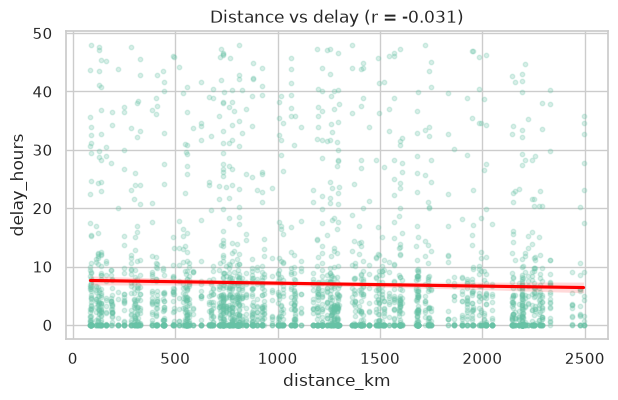

In [4]:
x, y = done["distance_km"], done["delay_hours"]
r_manual = ((x - x.mean()) * (y - y.mean())).sum() / np.sqrt(((x - x.mean())**2).sum() * ((y - y.mean())**2).sum())
r_stat, p_val = stats.pearsonr(x, y)
print(f"n = {len(x)} | r (manual) = {r_manual:.4f} | r (scipy) = {r_stat:.4f} | r² = {r_stat**2:.4f} | p = {p_val:.4f} -> {decide(p_val)}")
results.append({"test": "3. Pearson correlation", "question": "distance_km vs delay_hours", "n": len(x),
                "statistic": round(r_stat, 4), "p_value": round(p_val, 4), "decision": decide(p_val), "effect": f"r² = {r_stat**2:.4f}"})
fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(x=x, y=y, scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "red"}, ax=ax); ax.set_title(f"Distance vs delay (r = {r_stat:.3f})")
utils.save_fig(fig, "04_test3_pearson"); plt.show()

**Interpretation:** r = −0.03 (p ≈ 0.11, r² = 0.1%), so we fail to reject H₀. The correlation is about zero, so longer routes do **not** carry proportionally more delay. Distance drives transit time (r ≈ 0.94 with `delivery_hours`) but not lateness. Delays come from operational factors (warehouse, route-specific bottlenecks, day of week), so route planning should target specific lanes rather than penalising long-haul routes.

## Test 4: Spearman correlation (driver experience vs customer rating)
**Business question:** Do more experienced drivers receive better ratings (monotonic relationship)?
* H₀: ρ = 0 · H₁: ρ ≠ 0 · Formula: ρ = 1 − 6Σdᵢ² / (n(n²−1)) (on ranks) · Variables: driver experience (years), customer rating (each feedback record)

n = 3000 | rho (scipy) = 0.0300 | rho (rank-Pearson) = 0.0300 | rho (6Σd² formula, ties ignored) = 0.0785
p = 0.1002 -> Fail to reject H0
Driver-level (75 drivers, mean rating): rho = 0.1565, p = 0.1799


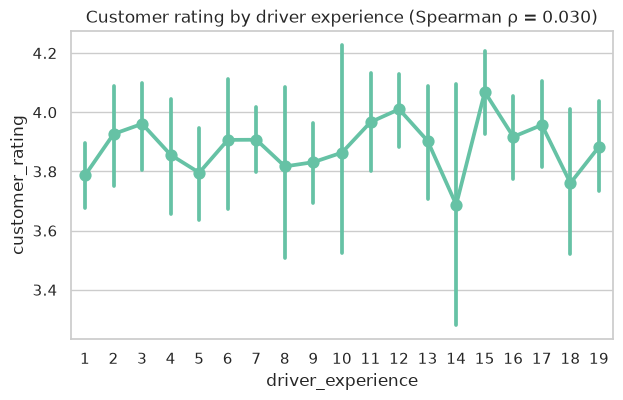

In [5]:
sub = df[["driver_experience", "customer_rating"]].dropna()
rho, p_val = stats.spearmanr(sub["driver_experience"], sub["customer_rating"])
# Manual check using the rank formula (average ranks for ties -> Pearson on ranks equals Spearman)
rx, ry = sub["driver_experience"].rank(), sub["customer_rating"].rank()
rho_manual = np.corrcoef(rx, ry)[0, 1]
d2 = ((rx - ry) ** 2).sum(); n = len(sub)
rho_formula = 1 - 6 * d2 / (n * (n**2 - 1))
print(f"n = {n} | rho (scipy) = {rho:.4f} | rho (rank-Pearson) = {rho_manual:.4f} | rho (6Σd² formula, ties ignored) = {rho_formula:.4f}")
print(f"p = {p_val:.4f} -> {decide(p_val)}")
drv = df.groupby("driver_id").agg(exp=("driver_experience", "first"), rating=("customer_rating", "mean"))
rho_d, p_d = stats.spearmanr(drv["exp"], drv["rating"])
print(f"Driver-level (75 drivers, mean rating): rho = {rho_d:.4f}, p = {p_d:.4f}")
results.append({"test": "4. Spearman correlation", "question": "driver experience vs customer rating", "n": n,
                "statistic": round(rho, 4), "p_value": round(p_val, 4), "decision": decide(p_val),
                "effect": f"driver-level rho {rho_d:.3f} (p={p_d:.3f})"})
fig, ax = plt.subplots(figsize=(7, 4))
sns.pointplot(data=df, x="driver_experience", y="customer_rating", ax=ax, errorbar=("ci", 95)); ax.set_title(f"Customer rating by driver experience (Spearman ρ = {rho:.3f})")
utils.save_fig(fig, "04_test4_spearman"); plt.show()

**Interpretation:** ρ = 0.03 (p ≈ 0.10), so we **fail to reject H₀**. At driver level the result is the same (ρ = 0.16, p ≈ 0.18). There is no meaningful monotonic link between years of experience and customer rating. Experience alone does not earn better ratings: Junior and Expert drivers differ by only about 0.1 stars on completed orders. Training should therefore focus on behaviours that prevent delays (planning, communication) rather than on tenure.

## Test 5: Z-score analysis (unusually high delays)
**Business question:** Which shipments have unusually high delays?
* Formula: Z = (X − μ) / σ · Variable: delay_hours (completed deliveries) · Threshold: |Z| > 3 → outlier

In [6]:
mu, sigma = done["delay_hours"].mean(), done["delay_hours"].std(ddof=0)
done["delay_z"] = (done["delay_hours"] - mu) / sigma
assert np.allclose(done["delay_z"], stats.zscore(done["delay_hours"]))
out = done[done["delay_z"].abs() > 3].sort_values("delay_z", ascending=False)
thr = mu + 3 * sigma
print(f"μ = {mu:.2f} h, σ = {sigma:.2f} h -> outlier threshold = {thr:.2f} h")
print(f"Outliers: {len(out)} shipments ({len(out)/len(done):.2%} of completed deliveries)")
cols = ["shipment_id", "shipment_dt", "warehouse_name", "warehouse_city", "driver_name", "route_name", "route_type", "vehicle_type", "delay_hours", "delay_z", "customer_rating"]
display(out[cols].head(15).round(2))
out[cols].to_csv(utils.PROJECT_ROOT / "reports" / "delay_outliers_zscore.csv", index=False)
results.append({"test": "5. Z-score analysis", "question": "delay_hours outliers |Z| > 3", "n": len(done),
                "statistic": round(thr, 2), "p_value": None, "decision": f"{len(out)} outliers flagged",
                "effect": f"threshold {thr:.1f} h; outlier avg rating {out['customer_rating'].mean():.2f} vs {done['customer_rating'].mean():.2f} overall"})

μ = 7.08 h, σ = 10.68 h -> outlier threshold = 39.13 h
Outliers: 90 shipments (3.32% of completed deliveries)


,shipment_id,shipment_dt,warehouse_name,warehouse_city,driver_name,route_name,route_type,vehicle_type,delay_hours,delay_z,customer_rating
1828,1829,2024-10-08 20:00:00,Warehouse_11,Chandigarh,Varun Patel,Mumbai -> Hyderabad,Standard,Van,47.97,3.83,4
1347,1348,2025-07-24 23:00:00,Warehouse_1,Mumbai,Ram Menon,Lucknow -> Mumbai,Standard,Bike,47.94,3.82,3
92,93,2025-06-27 11:00:00,Warehouse_7,Pune,Arjun Rao,Pune -> Ahmedabad,Express,Van,47.92,3.82,2
2340,2341,2024-10-21 13:00:00,Warehouse_8,Ahmedabad,Varun Kumar,Ahmedabad -> Kochi,Economy,Van,47.89,3.82,4
2144,2145,2025-04-30 18:00:00,Warehouse_1,Mumbai,Dinesh Nair,Jaipur -> Lucknow,Standard,Van,47.67,3.80,3
1681,1682,2025-03-05 13:00:00,Warehouse_11,Chandigarh,Sanjay Gupta,Kolkata -> Ahmedabad,Express,Truck,47.56,3.79,2
2709,2710,2025-10-25 06:00:00,Warehouse_3,Bangalore,Ramesh Reddy,Chennai -> Ahmedabad,Economy,Bike,47.34,3.77,2
732,733,2024-04-25 04:00:00,Warehouse_12,Kochi,Manoj Nair,Delhi -> Nagpur,Express,Truck,47.31,3.77,2
1346,1347,2024-04-22 16:00:00,Warehouse_3,Bangalore,Arjun Gupta,Kolkata -> Hyderabad,Economy,Van,47.27,3.76,3
403,404,2024-05-23 16:00:00,Warehouse_5,Chennai,Harsh Mehta,Kolkata -> Indore,Standard,Truck,47.25,3.76,3


,share_of_outliers,share_of_all,lift
route_type,,,
Express,0.244,0.204,1.20
Economy,0.233,0.211,1.11
Standard,0.522,0.585,0.89


,share_of_outliers,share_of_all,lift
vehicle_type,,,
Truck,0.567,0.484,1.17
Van,0.267,0.274,0.97
Bike,0.167,0.242,0.69


,share_of_outliers,share_of_all,lift
warehouse_city,,,
Kochi,0.133,0.072,1.86
Ahmedabad,0.111,0.070,1.59
Bangalore,0.089,0.066,1.35
Chennai,0.089,0.067,1.32
Nagpur,0.078,0.065,1.21


,share_of_outliers,share_of_all,lift
shipment_day_of_week,,,
Thursday,0.189,0.149,1.26
Monday,0.167,0.133,1.25
Tuesday,0.144,0.133,1.09
Friday,0.156,0.152,1.02
Sunday,0.133,0.140,0.95


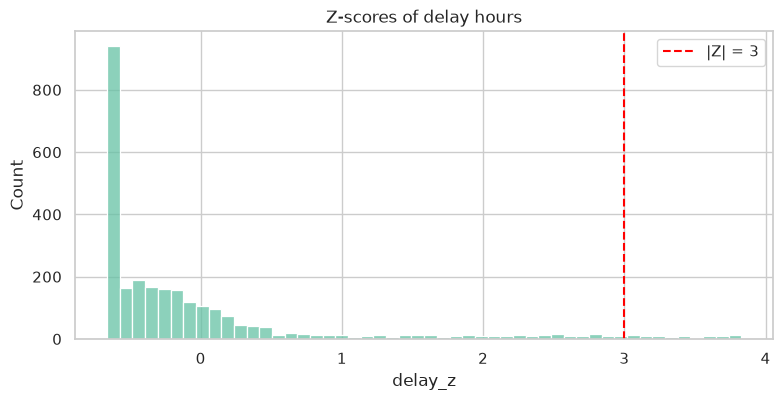

In [7]:
# Where do extreme delays concentrate? (over-representation vs share of all completed shipments)
def concentration(col):
    a = out[col].value_counts(normalize=True).rename("share_of_outliers")
    b = done[col].value_counts(normalize=True).rename("share_of_all")
    c = pd.concat([a, b], axis=1).fillna(0); c["lift"] = (c["share_of_outliers"] / c["share_of_all"]).round(2)
    return c.sort_values("lift", ascending=False).round(3)
for col in ["route_type", "vehicle_type", "warehouse_city", "shipment_day_of_week"]:
    display(concentration(col).head(5))
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(done["delay_z"], bins=50, ax=ax); ax.axvline(3, c="r", ls="--", label="|Z| = 3"); ax.legend(); ax.set_title("Z-scores of delay hours")
utils.save_fig(fig, "04_test5_zscore"); plt.show()

**Interpretation:** 90 shipments (3.3% of completed deliveries) are delayed by more than 39 h (μ + 3σ), close to two full days late. They average 2.8 stars against 4.1 for all completed orders. They are over-represented at the Kochi (1.9× lift) and Ahmedabad (1.6×) hubs, on trucks (1.2×), and on Monday and Thursday dispatches, so each one is a likely churn risk. They should be reviewed case by case with the warehouse and driver involved, and a delay above roughly 24 h should trigger proactive customer communication. With a right-skewed delay distribution, |Z| > 3 is a conservative screen. The IQR rule flags more.

## Supporting tests (beyond the brief)
These quantify the strongest EDA finding (delays → ratings) and the warehouse differences.

In [8]:
# A) Welch two-sample t-test: rating of on-time vs delayed deliveries (completed)
on_time = done.loc[done["is_delayed"] == 0, "customer_rating"]; late = done.loc[done["is_delayed"] == 1, "customer_rating"]
t_w, p_w = stats.ttest_ind(on_time, late, equal_var=False)
cohen_d = (on_time.mean() - late.mean()) / np.sqrt((on_time.var() + late.var()) / 2)
print(f"On-time mean {on_time.mean():.2f} (n={len(on_time)}) vs delayed mean {late.mean():.2f} (n={len(late)}): t = {t_w:.2f}, p = {p_w:.3g}, Cohen's d = {cohen_d:.2f}")
results.append({"test": "A. Welch t-test (supporting)", "question": "Rating on-time vs delayed", "n": len(on_time) + len(late),
                "statistic": round(t_w, 3), "p_value": float(f"{p_w:.4g}"), "decision": decide(p_w), "effect": f"Cohen's d = {cohen_d:.2f}"})
# Pearson delay vs rating
r_dr, p_dr = stats.pearsonr(done["delay_hours"], done["customer_rating"])
print(f"Pearson delay_hours vs rating: r = {r_dr:.3f}, p = {p_dr:.3g}")
results.append({"test": "B. Pearson (supporting)", "question": "delay_hours vs customer rating", "n": len(done),
                "statistic": round(r_dr, 4), "p_value": float(f"{p_dr:.4g}"), "decision": decide(p_dr), "effect": f"r² = {r_dr**2:.3f}"})
# C) Chi-square: is the 'Delivered' (success) outcome independent of warehouse?
ct = pd.crosstab(df["warehouse_name"], df["is_success"])
chi2, p_c, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square success vs warehouse: chi2 = {chi2:.2f}, dof = {dof}, p = {p_c:.4f} -> {decide(p_c)}")
results.append({"test": "C. Chi-square (supporting)", "question": "Success independent of warehouse?", "n": int(ct.values.sum()),
                "statistic": round(chi2, 3), "p_value": round(p_c, 4), "decision": decide(p_c), "effect": f"dof = {dof}"})

On-time mean 4.58 (n=775) vs delayed mean 3.91 (n=1937): t = 25.04, p = 2.07e-123, Cohen's d = 0.93
Pearson delay_hours vs rating: r = -0.591, p = 1.19e-255
Chi-square success vs warehouse: chi2 = 14.41, dof = 14, p = 0.4197 -> Fail to reject H0


## Results summary

In [9]:
res = pd.DataFrame(results)
res.to_csv(utils.PROJECT_ROOT / "reports" / "statistical_test_results.csv", index=False)
res

,test,question,n,statistic,p_value,decision,effect
0,1. Paired t-test,Delivery time Q1 vs Q2 (same drivers),75,-0.5804,5.634000e-01,Fail to reject H0,mean diff -0.63 h (Q1 26.63 h vs Q2 26.00 h)
1,2. One-sample t-test,Mean customer rating = 4.0?,3000,-5.5312,3.453000e-08,Reject H0,mean 3.893 (95% CI 3.856-3.931); completed-onl...
2,3. Pearson correlation,distance_km vs delay_hours,2712,-0.0310,1.062000e-01,Fail to reject H0,r² = 0.0010
3,4. Spearman correlation,driver experience vs customer rating,3000,0.0300,1.002000e-01,Fail to reject H0,driver-level rho 0.157 (p=0.180)
4,5. Z-score analysis,delay_hours outliers |Z| > 3,2712,39.1300,NaN,90 outliers flagged,threshold 39.1 h; outlier avg rating 2.79 vs 4...
5,A. Welch t-test (supporting),Rating on-time vs delayed,2712,25.0400,2.068000e-123,Reject H0,Cohen's d = 0.93
6,B. Pearson (supporting),delay_hours vs customer rating,2712,-0.5915,1.190000e-255,Reject H0,r² = 0.350
7,C. Chi-square (supporting),Success independent of warehouse?,3000,14.4090,4.197000e-01,Fail to reject H0,dof = 14


### Business conclusions
| # | Test | Business conclusion |
|---|---|---|
| 1 | Paired t-test | No significant change Q1→Q2 (p = 0.56). Performance is stable, so improvement requires intervention. |
| 2 | One-sample t-test | Mean rating 3.89 is **significantly below** the 4.0 target (p < 0.001). The gap is caused by cancelled, in-transit and severely delayed orders. |
| 3 | Pearson | r = −0.03, not significant: distance does **not** predict delay. Target specific bottleneck lanes and hubs, not long routes in general. |
| 4 | Spearman | ρ = 0.03, not significant: experience does not drive ratings. Coach delay-prevention behaviours rather than relying on tenure. |
| 5 | Z-score | 90 extreme delays (> 39 h, 3.3%) average 2.8 stars. They need case review and proactive alerts, starting with the Kochi and Ahmedabad hubs. |
| A/B | Welch / Pearson | **Delays are the main driver of satisfaction** (r = −0.59, r² = 35%; on-time 4.58 vs delayed 3.91 stars, d = 0.93). |
| C | Chi-square | p = 0.42: the warehouse success-rate spread (67-78%) is **not** statistically significant, so Jaipur and Nagpur should be monitored, not restructured, before acting on this alone. |